# 08 · Adressen sind keine Suchindizes

**NHyDB-0.28.2-Notebook-Reihe · v1**

Die Adresse beantwortet, **wo** ein Wert liegt. Sie beantwortet nicht, **welche** Datensätze einen bestimmten Wert enthalten – dafür hat NHyDB Sekundärindizes. Dieses Notebook zeigt ehrlich, was die Adresse leistet, was ein Index hinzufügt und wie beide zusammenarbeiten.

> **Für wen ist das?** Dieses Notebook beginnt mit einer kurzen Einführung und geht dann in ausführbare Beispiele über. **Neu bei NHyDB?** Lies von oben nach unten – jede Idee wird eingeführt, bevor sie verwendet wird. **Kennst du die Grundlagen schon?** Überspringe die mit 📘 *Hintergrund* markierten Abschnitte und springe zu den mit ▶ markierten Experimenten. Alle Zellen laufen von oben nach unten; optionale Vertiefungen sind mit ⏩ *Vertiefung* markiert.

**Was du lernst**

* den Unterschied zwischen dem Lesen über die Adresse und der Suche nach einem Wert
* die vier Indexfamilien VALUE, TOKEN, TRIGRAM und FULLTEXT (BM25)
* dass Indizes echte Datenstrukturen sind: `build_indexes()`, automatische Pflege und `StaleIndexError`
* wie der Abfrageplaner zwischen Index und Scan wählt (`explain`)
* wie groß der Geschwindigkeitsunterschied ist – gemessen auf deinem Rechner

**Vorher empfohlen:** [02 · Von der Mathematik zu gespeicherten Werten](02_from_address_to_data_v1.ipynb).

### Einrichtung

Die nächste Zelle prüft die Umgebung und definiert ein paar kleine Zeichenhilfen für dieses
Notebook. Sie ist eingeklappt, weil es darin nicht um NHyDB selbst geht – du kannst sie aber
gern öffnen. Jede Datenbank in diesem Notebook liegt in einem temporären Ordner, der am Ende
gelöscht wird.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.28.2"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

import random
import statistics
import time

import pandas as pd
from nhydb.query import Q, QueryEngine


def timed(fn, repeat=5):
    """Median and spread of `repeat` runs of fn() in milliseconds, plus the last result."""
    times, result = [], None
    for _ in range(repeat):
        t0 = time.perf_counter()
        result = fn()
        times.append((time.perf_counter() - t0) * 1000)
    return statistics.median(times), min(times), max(times), result

Python 3.14.5 · nhydb 0.28.2 · file format 0.28.2 · matplotlib 3.11.2


## 📘 Hintergrund: zwei verschiedene Fragen

| Frage | Beispiel | beantwortet durch |
|---|---|---|
| **Wo** ist es? Was steht in Datensatz 4242, Feld 2? | `get_value(1, 4242, 2)` | die **Adresse** – berechnet, keine Suche |
| **Welche** Datensätze haben city = „Reykjavik“? | `find_u(1, {"by_city": "Reykjavik"})` | einen **Sekundärindex** – oder einen vollständigen Scan |

Die Dynadron-Adresse löst das Identitätsproblem: Jede Zelle hat genau eine Zahl, nichts muss
nachgeschlagen werden. Ein *Wert* wie „Reykjavik“ kann dagegen in jedem beliebigen Datensatz
vorkommen – keine Formel kann wissen, wo. Das ist die Aufgabe eines Index: einer Datenstruktur,
die Werte auf Datensätze abbildet.

> Einen neuen Index baust du einmal mit `build_indexes()`. Danach **pflegt NHyDB ihn selbst**:
> Spätere Schreibvorgänge werden aus dem gebauten Index plus einem Overlay der geänderten
> Datensätze beantwortet, und nach genügend Änderungen erneuert die Engine den Index von sich aus.
> Ein Index, der nie gebaut wurde, ist *veraltet* (stale) – die Engine erkennt das.

## 1 · Ein Datenbestand mit 50.000 Personen

▶ **Ausprobieren:** Jede Person hat einen Namen, eine Stadt und ein Alter. Jede tausendste Person
lebt in Reykjavik, die übrigen verteilen sich auf acht andere Städte.

In [2]:
N_PEOPLE = 50_000                                   # ▶ Try it: dataset size
CITIES = ["Berlin", "Lisbon", "Kyoto", "Quito", "Oslo", "Lima", "Cairo", "Perth"]
random.seed(7)
people = [[f"person {i}", "Reykjavik" if i % 1000 == 0 else CITIES[i % 8], random.randint(18, 90)]
          for i in range(1, N_PEOPLE + 1)]

PATH = db_path("people.nhydb")
with nhydb.create(PATH) as db:
    db.create_realm(1, "people")
    db.create_shape(1, 1, "person", [{"v": 1, "name": "name", "type": "utf8"},
                                     {"v": 2, "name": "city", "type": "utf8"},
                                     {"v": 3, "name": "age", "type": "u8"}])
    db.create_classic_layout(1, 1, "people", shape_id=1)
    db.put_dense_batch(1, 1, people, shape_id=1)
print(f"{N_PEOPLE:,} records written; file size {os.path.getsize(PATH):,} bytes")
truth_reykjavik = [u for u, p in enumerate(people, start=1) if p[1] == "Reykjavik"]

50,000 records written; file size 1,198,200 bytes


## 2 · Adresse vs. Scan vs. Index

**Frage:** Wie lange braucht jeder der drei Wege?

1. **Über die Adresse:** die Stadt von Datensatz 4242 lesen – die Zelle wird berechnet, keine Suche.
2. **Scan:** alle Reykjavik-Datensätze **ohne Index** finden – jeder Datensatz muss gelesen werden.
3. **Index:** dieselbe Frage mit einem VALUE-Index auf `city`.

Jede Messung wird fünfmal wiederholt; die Balken zeigen den Median, die dünnen Linien die Spannweite.

In [3]:
db = nhydb.open(PATH)
q = QueryEngine(db)

addr = timed(lambda: db.get_value(1, 4242, 2))
plan_scan = q.explain(Q.field("city") == "Reykjavik", realm=1)["plan"]
scan = timed(lambda: q.execute(Q.field("city") == "Reykjavik", realm=1, return_mode="n")["refs"])

db.create_index(1, 1, "by_city", "city")
build = db.build_indexes(commit=True)
plan_index = q.explain(Q.field("city") == "Reykjavik", realm=1)["plan"]
index = timed(lambda: q.execute(Q.field("city") == "Reykjavik", realm=1, return_mode="n")["refs"])

assert addr[3] == people[4241][1]
assert scan[3] == index[3] and len(index[3]) == len(truth_reykjavik)
print(f"plan without index: {plan_scan['access']:18} estimated rows {plan_scan['estimated_rows']:,}")
print(f"plan with index   : {plan_index['access']:18} estimated rows {plan_index['estimated_rows']:,}")
print(f"index build: {build['total_s'] * 1000:.1f} ms, index payload {build['indexes'][0]['payload_bytes']:,} bytes, "
      f"{build['indexes'][0]['distinct_values']} distinct cities")

plan without index: MATERIALIZED_SCAN  estimated rows 50,000
plan with index   : VALUE_INDEX        estimated rows 50
index build: 7.8 ms, index payload 53,230 bytes, 9 distinct cities


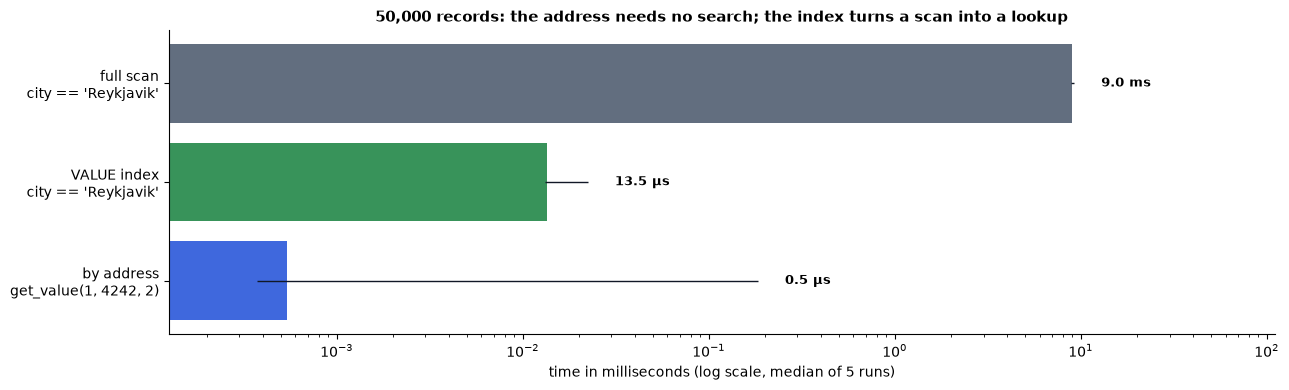

In [4]:
results = pd.DataFrame([
    {"way": "by address\nget_value(1, 4242, 2)", "median ms": addr[0], "min": addr[1], "max": addr[2], "layer": "A"},
    {"way": "VALUE index\ncity == 'Reykjavik'", "median ms": index[0], "min": index[1], "max": index[2], "layer": "B"},
    {"way": "full scan\ncity == 'Reykjavik'", "median ms": scan[0], "min": scan[1], "max": scan[2], "layer": "C"},
])
fig, ax = plt.subplots(figsize=(13, 4))
y = range(len(results))
ax.barh(y, results["median ms"], color=[COLORS[l] for l in results["layer"]], alpha=0.85)
ax.hlines(y, results["min"], results["max"], color="#111827", lw=1)
for yi, m, hi in zip(y, results["median ms"], results["max"]):
    label = f"{m * 1000:.1f} µs" if m < 0.1 else f"{m:.1f} ms"
    ax.text(max(m, hi) * 1.4, yi, label, va="center", fontsize=9, fontweight="bold")
ax.set_yticks(list(y))
ax.set_yticklabels(results["way"])
ax.set_xscale("log")
ax.set_xlabel("time in milliseconds (log scale, median of 5 runs)")
ax.set_title(f"{N_PEOPLE:,} records: the address needs no search; the index turns a scan into a lookup")
ax.set_xlim(results["min"].min() / 3, results["max"].max() * 12)
plt.tight_layout()
plt.show()

**Was ist passiert?**

* **Adresse:** Mikrosekunden – die Engine berechnet, wo Datensatz 4242, Feld 2 liegt, und liest ihn.
  Keine Suche, kein Index, unabhängig von der Größe der Datenbank. (Die lange dünne Linie ist der
  allererste Lesezugriff, der auch den Datenblock in den Speicher lädt.)
* **Scan:** Jeder der 50.000 Datensätze wird gelesen und verglichen (`MATERIALIZED_SCAN`).
* **Index:** Der Planer wechselt zu `VALUE_INDEX` und liest nur die passenden Einträge. Die Zahlen
  hängen von deinem Rechner ab – vergleiche ihr Verhältnis, nicht die absoluten Werte.

**Ah – die Adresse macht Identität kostenlos; der Index macht die Wertsuche schnell. Sie lösen
zwei verschiedene Probleme.**

## 3 · Indizes bleiben aktuell – und die Engine merkt, wenn sie es nicht können

**Frage:** Was passiert, wenn nach dem Aufbau des Index Daten geschrieben werden?

▶ **Ausprobieren:** Wir fügen eine weitere Person aus Reykjavik hinzu, **ohne** `build_indexes()` erneut aufzurufen.

In [5]:
db.put(1, N_PEOPLE + 1, ["late arrival", "Reykjavik", 33], commit=True)

direct = list(db.find_u(1, {"by_city": "Reykjavik"}))      # direct index API
plan = q.explain(Q.field("city") == "Reykjavik", realm=1)["plan"]
count = q.execute(Q.field("city") == "Reykjavik", realm=1, return_mode="count")["count"]
state = next(c for c in db.health()["checks"] if c["name"] == "indexes")["details"]
print(f"find_u      → {len(direct)} records (includes the new record)")
print(f"QueryEngine → plan {plan['access']}, count = {count}")
print(f"health()    → maintenance {state['maintenance']['maintenance']!r}, overlay {state['overlay']}")
assert len(direct) == count == len(truth_reykjavik) + 1 and plan["access"] == "VALUE_INDEX"

find_u      → 51 records (includes the new record)
QueryEngine → plan VALUE_INDEX, count = 51
health()    → maintenance 'auto', overlay ['by_city/NL']


**Was ist passiert?** Der Index hat ohne Neuaufbau richtig geantwortet. NHyDB pflegt Indizes
automatisch (`[index] maintenance = "auto"`, die Voreinstellung): Nach einem Schreibvorgang
antwortet ein Index aus seinem gebauten Teil plus einem **Overlay** der geänderten Datensätze im
Arbeitsspeicher, und ein späterer Commit erneuert den Index von sich aus, sobald sich genügend
Datensätze geändert haben (voreingestellt 2 %). `health()` zeigt das Overlay; `verify()` nennt es
bis zur Erneuerung als Warnung.

**Veraltet ist nur ein Index, der noch nie gebaut wurde.** ▶ **Ausprobieren:** Wir legen einen
zweiten Index an, auf `age`, bauen ihn aber noch nicht.

In [6]:
db.create_index(2, 1, "by_age", "age")
thirties = sum(1 for p in people if 30 <= p[2] <= 39) + 1          # + the late arrival (33)
try:
    list(db.find_u(1, {"by_age": (30, 39)}))                     # direct index API
except nhydb.StaleIndexError as e:
    print("find_u      →", type(e).__name__, ":", e)

stale_plan = q.explain(Q.field("age").between(30, 39), realm=1)["plan"]
count = q.execute(Q.field("age").between(30, 39), realm=1, return_mode="count")["count"]
print(f"QueryEngine → falls back to {stale_plan['access']}, count = {count:,} (correct)")
assert count == thirties and stale_plan["access"] == "MATERIALIZED_SCAN"

db.build_indexes(commit=True)
fresh = list(db.find_u(1, {"by_age": (30, 39)}))
print(f"after build_indexes(): {len(fresh):,} records via index, plan "
      f"{q.explain(Q.field('age').between(30, 39), realm=1)['plan']['access']}")
assert len(fresh) == thirties and db.verify()["ok"]

find_u      → StaleIndexError : Index 'by_age'/NL is missing or older than the data. Run build_indexes().
QueryEngine → falls back to MATERIALIZED_SCAN, count = 6,746 (correct)
after build_indexes(): 6,746 records via index, plan VALUE_INDEX


**Was ist passiert?** Zwei verschiedene Sicherheitsreaktionen, beide beabsichtigt:

* Die **direkte Index-API** weigert sich, aus einem Index ohne gebauten Teil zu antworten
  (`StaleIndexError`) – eine falsche Antwort wird nie zurückgegeben.
* Die **QueryEngine** wechselt stillschweigend zu einem Scan; die Antwort ist also weiterhin
  richtig, nur langsamer.

Nach `build_indexes()` wird der Index verwendet und von da an gepflegt. Mit
`[index] maintenance = "manual"` in der Konfigurationsdatei bleibt das Erneuern dir überlassen –
zum Beispiel `build_indexes()` in einem Wartungsfenster nach einem großen Import.

## 4 · Textindizes: TOKEN, TRIGRAM und FULLTEXT

**Frage:** Wie suchen wir innerhalb von Text?

| Index | beantwortet | Beispiel |
|---|---|---|
| **TOKEN** | enthält ganze Wörter (ohne Beachtung der Groß-/Kleinschreibung) | `token("lane")` |
| **TRIGRAM** | enthält eine Teilzeichenkette | `icontains("adro")` |
| **FULLTEXT** | Wörter und Phrasen, nach Relevanz gerankt (BM25) | `fulltext("prime numbers")` |

Eine kleine Bibliothek von Artikeln, die sich mit bloßem Auge überprüfen lassen:

In [7]:
ARTICLES = [
    ["The Dynadron", "the Dynadron arranges all natural numbers in groups around the squares"],
    ["Two lanes", "every cell has a left lane NL and a right lane NR with different numbers"],
    ["Boundary points", "squares and products of neighbours are boundary points, not cells"],
    ["Prime numbers", "prime numbers appear in both halves of every group of the Dynadron"],
    ["Realms", "a realm is a stretch of ten to the power of one hundred positions"],
    ["Indexes", "an index maps values to records; it is built once and then maintained"],
    ["Prime gaps", "gaps between prime numbers grow slowly; prime numbers never stop"],
    ["Layouts", "a layout decides how records and fields are placed on cells"],
]
TPATH = db_path("articles.nhydb")
with nhydb.create(TPATH) as tdb:
    tdb.create_realm(1, "kb")
    tdb.create_shape(1, 1, "article", [{"v": 1, "name": "title", "type": "utf8"},
                                       {"v": 2, "name": "body", "type": "utf8"}])
    tdb.create_classic_layout(1, 1, "articles", shape_id=1)
    tdb.put_dense_batch(1, 1, ARTICLES, shape_id=1)
    tdb.create_token_index(1, 1, "tok_body", "body")
    tdb.create_trigram_index(2, 1, "tri_title", "title", casefold=True)
    tdb.create_fulltext_index(3, 1, "ft_body", "body")
    tdb.build_indexes(commit=True)

    def titles(us):
        return [ARTICLES[u - 1][0] for u in us]

    print("TOKEN    'lane'          →", titles(tdb.index_candidates(1, "token", "lane")))
    print("TOKEN    all 'prime gaps' →", titles(tdb.index_candidates(1, "tokens_all", "prime gaps")))
    print("TRIGRAM  icontains 'ADRO' →", titles(tdb.index_candidates(2, "icontains", "ADRO")))
    print("FULLTEXT phrase 'boundary points' →", titles(tdb.index_candidates(3, "phrase", "boundary points")))
    assert titles(tdb.index_candidates(1, "token", "lane")) == ["Two lanes"]
    assert titles(tdb.index_candidates(2, "icontains", "ADRO")) == ["The Dynadron"]

    SEARCH = "prime numbers"                         # ▶ Try it: your own search words
    hits = QueryEngine(tdb).search(Q.fulltext("body", SEARCH), realm=1, select=["title"], limit=8)["rows"]
ranking = pd.DataFrame([{"title": h["title"], "BM25 relevance": round(h["relevance"], 3)} for h in hits])
ranking

TOKEN    'lane'          → ['Two lanes']
TOKEN    all 'prime gaps' → ['Prime gaps']
TRIGRAM  icontains 'ADRO' → ['The Dynadron']
FULLTEXT phrase 'boundary points' → ['Boundary points']


,title,BM25 relevance
0,Prime gaps,2.848
1,Prime numbers,1.974


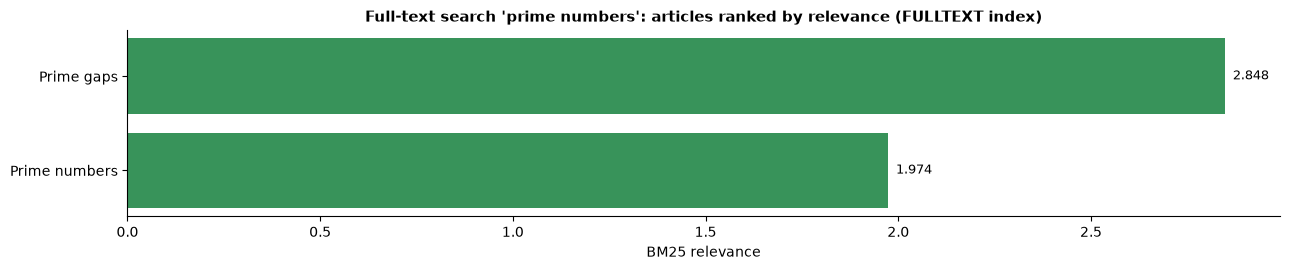

In [8]:
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.barh(ranking["title"][::-1], ranking["BM25 relevance"][::-1], color=COLORS["B"], alpha=0.85)
for i, v in enumerate(ranking["BM25 relevance"][::-1]):
    ax.text(v + 0.02, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("BM25 relevance")
ax.set_title(f"Full-text search '{SEARCH}': articles ranked by relevance (FULLTEXT index)")
plt.tight_layout()
plt.show()

**Was ist passiert?** „Prime gaps“ erwähnt *prime numbers* zweimal und steht an erster Stelle;
„Prime numbers“ folgt. Artikel, die keines der beiden Wörter erwähnen, erscheinen nicht. BM25 ist
eine Standard-Rankingformel aus dem Information Retrieval: Häufige Wörter in kurzen Texten zählen
mehr, Wörter, die in jedem Dokument vorkommen, zählen weniger.

## 5 · Was der Planer wählt

`explain` zeigt für jede Art von Frage, wie die Engine sie beantworten wird – bevor sie ausgeführt
wird. Strukturelle Fragen zu `u`, `v` oder `N` werden über die **Adresse** beantwortet,
Wertfragen über einen **Index**, wenn ein gebauter existiert, sonst über einen **Scan**.

In [9]:
questions = {
    "city == 'Oslo'":          Q.field("city") == "Oslo",
    "age between 30 and 39":   Q.field("age").between(30, 39),
    "name == 'person 77'":     Q.field("name") == "person 77",
    "u between 100 and 200":   Q.u.between(100, 200),
    "city == 'Oslo' and age < 20": (Q.field("city") == "Oslo") & (Q.field("age") < 20),
}
rows = []
for text, expr in questions.items():
    plan = q.explain(expr, realm=1)["plan"]
    rows.append({"question": text, "access": plan.get("access", plan.get("node")),
                 "index": plan.get("index_name") or "–", "estimated rows": plan.get("estimated_rows")})
pd.DataFrame(rows).set_index("question")

,access,index,estimated rows
question,,,
city == 'Oslo',VALUE_INDEX,by_city,6250
age between 30 and 39,VALUE_INDEX,by_age,6746
name == 'person 77',MATERIALIZED_SCAN,–,50001
u between 100 and 200,STRUCT_RANGE,–,101
city == 'Oslo' and age < 20,AND,–,6250


`name` hat keinen Index, also scannt der Planer. Für die kombinierte Frage ist der Plan ein Baum
(`AND`); `db.explain_query(...)` / `q.explain(...)` liefern den vollständigen Baum zur Ansicht.

## Jetzt du

**Aufgabe:** Wie viele Personen in Berlin sind zwischen 30 und 39 Jahre alt? Verwende die beiden
Indizes mit `db.find(...)` und prüfe die Antwort dann mit einfachem Python an der ursprünglichen
Liste.

In [10]:
found = list(db.find(1, {"by_city": "Berlin", "by_age": (30, 39)}))
truth = sum(1 for p in people if p[1] == "Berlin" and 30 <= p[2] <= 39)
print(f"index answer: {len(found)}   plain Python: {truth}")
assert len(found) == truth and all(r["city"] == "Berlin" and 30 <= r["age"] <= 39 for r in found)

index answer: 875   plain Python: 875


## ⏩ Vertiefung: Schätzungen und Kosten

Ein Index beantwortet auch, *wie viele* es sind, ohne einen einzigen Datensatz zu lesen, und seine
Größe ist Teil der Datei. Indizes kosten Platz und Aufbauzeit. (Die Datei ist append-only: Jeder
Aufbau und jede automatische Erneuerung schreibt neue Indexblöcke; die älteren bleiben bis zu
einer Kompaktierung erhalten – Notebook 11.)

In [11]:
print("posting count 'Reykjavik':", db.posting_count(1, "Reykjavik"))
print("estimate age 30–39       :", db.index_candidate_estimate(2, "between", 30, 39))
stats = db.stats()["storage"]["by_block_type"]
print({k: v["bytes"] for k, v in stats.items()})
db.close()

posting count 'Reykjavik': 51
estimate age 30–39       : {'estimated_rows': 6746, 'exact': True, 'key_count': 1}
{'DATA_DENSE': 1189176, 'DB_CONFIG': 104, 'SECONDARY_INDEX': 1424, 'SECONDARY_PAGE': 203064, 'SYSTEM_R0_U1': 1464}


## Zusammenfassung

* Die Adresse beantwortet das *Wo*: Eine bekannte Zelle zu lesen braucht keine Suche und keinen Index.
* Die Suche nach einem Wert braucht einen Index (VALUE, TOKEN, TRIGRAM, FULLTEXT) – oder einen vollständigen Scan.
* Ein neuer Index wird einmal mit `build_indexes()` gebaut und dann automatisch gepflegt; ein nie gebauter Index wird erkannt: Direkte APIs verweigern, die QueryEngine scannt.
* `explain` zeigt, ob eine Antwort aus der Adresse, einem Index oder einem Scan kommt.

## Wie es weitergeht

* [09 · Fragen an die Daten](09_queries_and_sql_v1.ipynb) – QueryEngine und NHySQL im Detail.
* [13 · Messen statt vermuten](13_benchmark_lab_v1.ipynb) – größere, wiederholbare Messungen.

**Cookbook-Abschnitte:** 13 (Sekundärindizes), 14 (QueryEngine) im [NHyDB Python Cookbook](https://github.com/nhydb-run4/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [12]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
